# SPS flange wakefield with CPML and TF/SF: staircase vs conformal mesh

Same test case as notebook `001e`: the SPS pipe-flange transition, a 1 nC Gaussian beam offset by 5 mm in x,
CPML at both longitudinal ends with Total-Field/Scattered-Field injection, and a 5 m wakelength.

Notebook `001e` shows a parasitic peak around 2.2 GHz in the transverse impedance, which shrinks with finer
transverse resolution. Here the case is run twice on the **same coarse grid**:

* **staircase**: the legacy cell mask (`geometry_mode="legacy"`, `voxelize_rectilinear`), as in `001e`;
* **conformal**: cut-cell geometry (`geometry_mode="conformal"`) with the area-floor small-cell treatment.

Both runs share grid, beam, CPML and wake settings, so differences in the wake potentials and impedances
come from the geometry representation alone. The grid is much coarser than in `001e` to get results quickly.

## Imports

In [1]:
import sys
from pathlib import Path

# Use the Wakis version of this repository, not another installed copy.
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv

import wakis
from wakis import GridFIT3D, SolverFIT3D, WakeSolver

print("Wakis imported from:", Path(wakis.__file__).parent)
%matplotlib inline

Wakis imported from: /home/hschreib/Documents/Wakis/WAKIS/wakis


## Geometry

Same solids as in `001e`: a pipe of radius 41.5 mm and a flange cavity of radius 78 mm and length 100 mm.
The pipe is made 20 mm longer than the 300 mm domain so its ends lie outside the computational domain. The
geometry inside the domain is unchanged, but no grid plane coincides with an STL end cap, which would make
the conformal edge tracing degenerate at the domain boundary. The domain bounds are set explicitly to those
of `001e`.

In [2]:
results_folder = Path("001f_results")
results_folder.mkdir(exist_ok=True)

pipe = pv.Cylinder(
    radius=41.5, height=320, direction=(0, 0, 1), center=(0, 0, 0)
).scale(1e-3)
cyl = pv.Cylinder(radius=78, height=100, direction=(0, 0, 1), center=(0, 0, 0)).scale(
    1e-3
)
stl_file = str(results_folder / "SPS_400_pipe_trans_QF_B2_merged_m.stl")
(pipe.triangulate() | cyl.triangulate()).save(stl_file)

stl_solids = {"transition": stl_file}
stl_materials = {"transition": "vacuum"}

# Domain of notebook 001e
xmin, xmax, ymin, ymax, zmin, zmax = -0.078, 0.078, -0.078, 0.078, -0.15, 0.15

## Grid

`Nx`, `Ny`, `Nz` count primal nodes (symmetric FIT stencil), so the number of cells is one less per axis.

* Transverse: 32 cells, dx = dy = 4.875 mm (`001e`: 1.55 mm). With an even cell count x = 0 is a grid
  line, and the 5 mm source lies 0.125 mm from the nearest line.
* Longitudinal: 100 cells, dz = 3 mm (`001e`: 1 mm), i.e. 5 cells per bunch length sigma_z = 15 mm.

Increase `Nx`, `Ny`, `Nz` for a convergence study; keep the transverse cell count even.

In [3]:
Nx, Ny, Nz = 33, 33, 101
print(
    f"Cells: {(Nx - 1) * (Ny - 1) * (Nz - 1)}, dx = {(xmax - xmin) / (Nx - 1) * 1e3:.3f} mm, "
    f"dz = {(zmax - zmin) / (Nz - 1) * 1e3:.3f} mm"
)

geometry = {
    "staircase": dict(geometry_mode="legacy", stl_method="voxelize_rectilinear"),
    "conformal": dict(
        geometry_mode="conformal",
        stl_method="interior_points",
        stl_material_types={"transition": "normal"},
        bg_material_type="pec",  # everything outside the STL is PEC (bg="pec" below)
        conformal_stabilization="area_floor",
        conformal_stabilization_fraction=0.1,
    ),
}

grids = {
    name: GridFIT3D(
        xmin,
        xmax,
        ymin,
        ymax,
        zmin,
        zmax,
        Nx,
        Ny,
        Nz,
        stl_solids=stl_solids,
        stl_materials=stl_materials,
        verbose=0,
        **kwargs,
    )
    for name, kwargs in geometry.items()
}

Cells: 102400, dx = 4.875 mm, dz = 3.000 mm
Generating grid with 109989 mesh cells...
Generating grid with 109989 mesh cells...


/home/hschreib/Documents/Wakis/WAKIS/wakis/conformal.py:3063: UserWarning: Conformal geometry diagnostics:
26 endpoint interface edges have no geometric crossing and will not receive a conformal correction.
5 edges contain geometric crossings that are hidden from endpoint topology and are ignored by the current conformal discretization.
  self._warn_interface_diagnostics()


## Beam, wake and solver settings

Identical to `001e`. With CPML, TF/SF injection is used, and `skip_cells = n_pml + 3` excludes the CPML and
injection cells from the wake integration.

In [4]:
sigmaz = 15e-3  # [m]
q = 1e-9  # [C]
beta = 1.0
xs, ys = 0.005, 0.0  # source position [m]
xt, yt = 0.0, 0.0  # test position [m]
wakelength = 5.0  # [m]
n_pml = 4
skip_cells = n_pml + 3

cpml = dict(n_pml=n_pml, alpha_max=0.1, kappa_max=10.0, pml_exp=4, sigma_factor=1.0)

grid = grids["staircase"]
print(
    f"Source on the grid line x = {grid.x[np.abs(grid.x - xs).argmin()] * 1e3:.3f} mm "
    f"(requested {xs * 1e3:.1f} mm)"
)

Source on the grid line x = 4.875 mm (requested 5.0 mm)


## Run both simulations

In [5]:
wakes, solvers = {}, {}
for name, grid in grids.items():
    print(f"\n========== {name} ==========")
    folder = results_folder / name
    wake = WakeSolver(
        q=q,
        sigmaz=sigmaz,
        beta=beta,
        xsource=xs,
        ysource=ys,
        xtest=xt,
        ytest=yt,
        results_folder=f"{folder}/",
        skip_cells=skip_cells,
        Ez_file=f"{folder}/Ez.h5",
        verbose=0,
    )
    solver = SolverFIT3D(
        grid,
        wake,
        bc_low=["pec", "pec", "cpml"],
        bc_high=["pec", "pec", "cpml"],
        use_stl=True,
        bg="pec",
        verbose=0,
        **cpml,
    )
    if name == "conformal":
        # Cut cells lower the stable time step; the area floor keeps it above dt.
        stability = solver.compute_stable_timestep(verbose=False)
        print(
            f"dt / dt_max = {stability['dt_ratio']:.3f}, stable: {stability['stable']}"
        )
    solver.wakesolve(wakelength=wakelength, wake=wake)
    wakes[name], solvers[name] = wake, solver


========== staircase ==========
Initializing Electromagnetic solver...
Running electromagnetic time-domain simulation...


  0%|          | 0/4797 [00:00<?, ?it/s]

  0%|          | 12/4797 [00:00<00:41, 114.13it/s]

  1%|          | 24/4797 [00:00<00:41, 115.23it/s]

  1%|          | 36/4797 [00:00<00:41, 115.35it/s]

  1%|          | 48/4797 [00:00<00:41, 115.57it/s]

... (746 outputs left out)

 92%|█████████▏| 37645/40797 [00:07<00:00, 4291.34it/s]

 96%|█████████▋| 39366/40797 [00:07<00:00, 5650.58it/s]

100%|██████████| 40797/40797 [00:07<00:00, 5111.17it/s]

Calculating transverse wake potential WPx, WPy...
Calculating longitudinal impedance Z...
Calculating transverse impedance Zx, Zy...


### Mirror symmetry of the discrete geometry

The geometry is symmetric under x -> -x and y -> -y. Ez is stored on the grid lines (x_i, y_j), so a
symmetric discretisation has the same set of active Ez lines after mirroring the index j -> Ny-1-j.
The staircase mask takes the material of each edge from the cell on its high side, which shifts the
discrete geometry by half a cell; the conformal geometry keeps the symmetry.

In [7]:
k_mid = (Nz - 1) // 2  # cavity mid-plane
for name, solver in solvers.items():
    active = (solver.ieps.to_matrix("z") * solver.L.to_matrix("z"))[:, :, k_mid] != 0
    print(
        f"{name:10s}: mirror-x mismatches {np.sum(active != active[::-1, :]):3d}, "
        f"mirror-y mismatches {np.sum(active != active[:, ::-1]):3d}"
    )

staircase : mirror-x mismatches  50, mirror-y mismatches  50
conformal : mirror-x mismatches   0, mirror-y mismatches   0


## Compare results

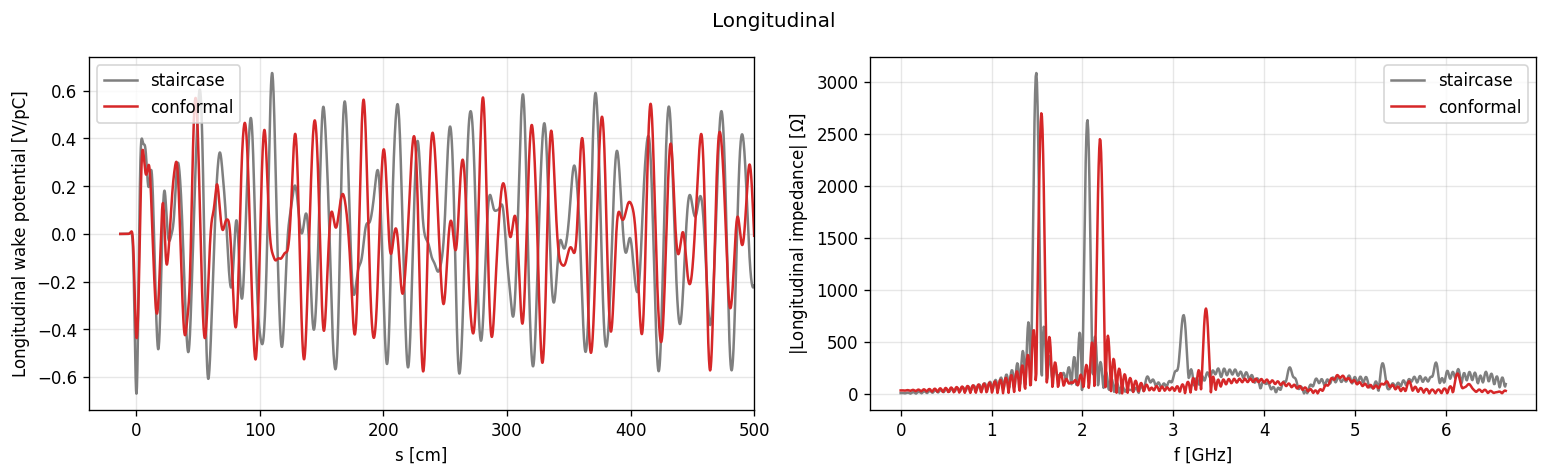

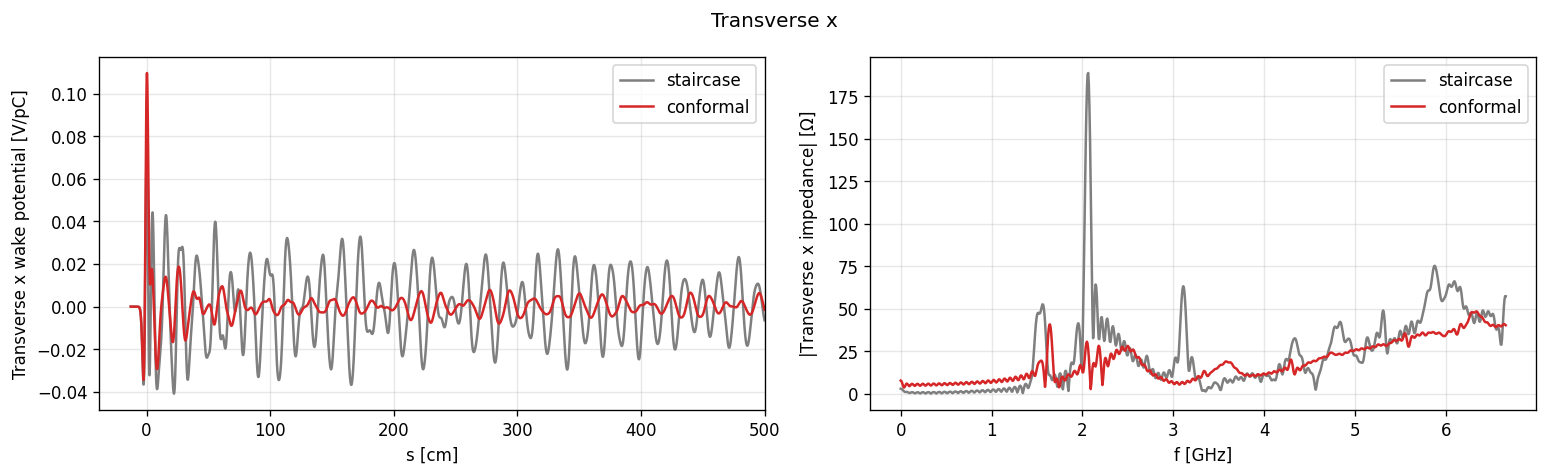

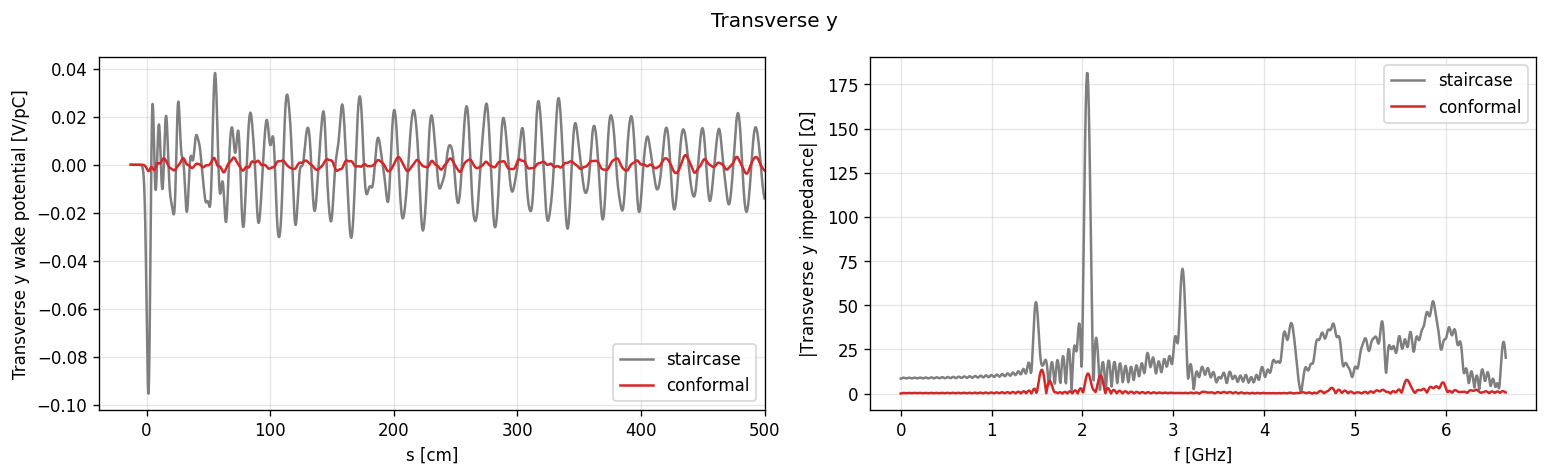

In [8]:
styles = {
    "staircase": dict(c="tab:gray", lw=1.5),
    "conformal": dict(c="tab:red", lw=1.5),
}


def compare(quantity, s_key, f_key, label):
    fig, ax = plt.subplots(1, 2, figsize=[13, 4], dpi=120)
    for name, wake in wakes.items():
        ax[0].plot(wake.s * 1e2, getattr(wake, s_key), label=name, **styles[name])
        ax[1].plot(
            getattr(wake, f_key[0]) * 1e-9,
            np.abs(getattr(wake, f_key[1])),
            label=name,
            **styles[name],
        )
    ax[0].set(
        xlabel="s [cm]",
        ylabel=f"{label} wake potential [V/pC]",
        xlim=(None, wakelength * 1e2),
    )
    ax[1].set(xlabel="f [GHz]", ylabel=f"|{label} impedance| [$\\Omega$]")
    for a in ax:
        a.grid(alpha=0.3)
        a.legend()
    fig.suptitle(quantity)
    fig.tight_layout()
    fig.savefig(results_folder / f"{s_key}.png")
    plt.show()


compare("Longitudinal", "WP", ("f", "Z"), "Longitudinal")
compare("Transverse x", "WPx", ("fx", "Zx"), "Transverse x")
compare("Transverse y", "WPy", ("fy", "Zy"), "Transverse y")

### Low-frequency zoom of the transverse x impedance

The region of the parasitic peak reported in `001e` (about 2.2 GHz).

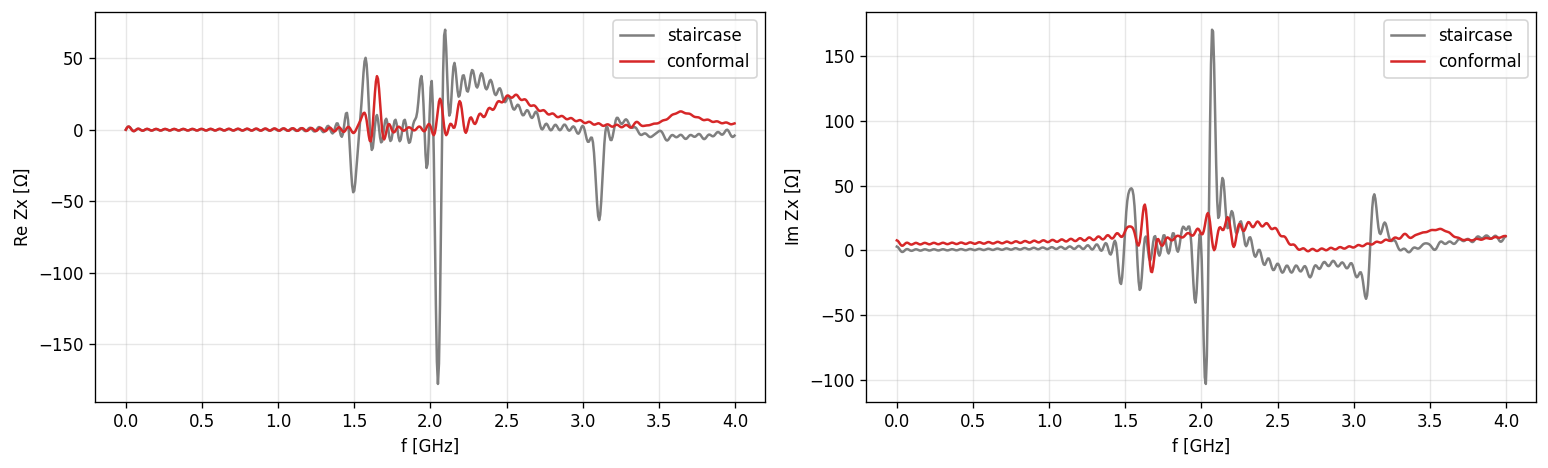

staircase : max |Zx| in 1.8-2.6 GHz =   188.76 Ohm at 2.063 GHz, max |WPx| = 0.0716 V/pC
conformal : max |Zx| in 1.8-2.6 GHz =    30.62 Ohm at 2.050 GHz, max |WPx| = 0.1097 V/pC


In [9]:
fig, ax = plt.subplots(1, 2, figsize=[13, 4], dpi=120)
for name, wake in wakes.items():
    mask = wake.fx < 4e9
    ax[0].plot(wake.fx[mask] * 1e-9, np.real(wake.Zx[mask]), label=name, **styles[name])
    ax[1].plot(wake.fx[mask] * 1e-9, np.imag(wake.Zx[mask]), label=name, **styles[name])
ax[0].set(xlabel="f [GHz]", ylabel="Re Zx [$\\Omega$]")
ax[1].set(xlabel="f [GHz]", ylabel="Im Zx [$\\Omega$]")
for a in ax:
    a.grid(alpha=0.3)
    a.legend()
fig.tight_layout()
plt.show()

for name, wake in wakes.items():
    band = (wake.fx > 1.8e9) & (wake.fx < 2.6e9)
    k = np.argmax(np.abs(wake.Zx[band]))
    print(
        f"{name:10s}: max |Zx| in 1.8-2.6 GHz = {np.abs(wake.Zx[band][k]):8.2f} Ohm "
        f"at {wake.fx[band][k] * 1e-9:.3f} GHz, max |WPx| = {np.abs(wake.WPx).max():.4f} V/pC"
    )

## Observations on the coarse grid

* **Symmetry.** The beam is at y = 0 in a geometry that is mirror-symmetric in y, so the vertical wake
  must vanish. The conformal run gives a vertical wake close to zero; the staircase run does not, because
  its discrete geometry is shifted by half a cell (see the symmetry check above).
* **Parasitic transverse peaks.** The large staircase peaks in |Zx| and |Zy| sit at the frequencies of its
  longitudinal (monopole) resonances. An off-centre discrete geometry couples monopole modes into the
  transverse wake. The offset scales with the cell size, which is why a finer grid reduces the peak in
  `001e`. With the conformal geometry these peaks are largely gone already on this coarse grid.
* **Longitudinal resonances.** The resonance frequencies differ between the two runs by a few percent.
  Which one is closer to the converged result needs a finer grid (increase `Nx`, `Ny`, `Nz`).

## Comparison with CST results

CST Wakefield Solver results for the same geometry in `SPS_trans_results/` (pipe r = 41.5 mm, l = 320 mm;
cylinder r = 78 mm, l = 100 mm; beam at x = 5 mm, y = 0; 5 m wakelength). The files contain the
longitudinal (`W_z`, `Z_z`) and horizontal (`W_x`, `Z_x`) wake potential and impedance. The vertical wake
is close to zero in CST and was not exported.

**Sign convention:** for the same wake potential, CST's transverse impedance has the opposite sign of the
Wakis one (CST: Z⊥ = -i FT(W⊥)/FT(λ), Wakis: +i). Applying the Wakis formula to the CST `W_x` reproduces
the CST `Z_x` with flipped sign to 1 %, and the CST `Z_z` with the same sign to 2 %. The CST `Z_x` is
therefore multiplied by -1 below; the longitudinal convention is the same in both codes.

Differences to keep in mind: the CST mesh setting is `nmesh = 20` (cells per wavelength); here the grid is
coarse (dx = 4.875 mm) and the 5 mm source snaps to the nearest grid line at 4.875 mm.

In [10]:
cst_folder = Path("SPS_trans_results")


def load_cst(name):
    """Load a CST text export: columns are s [mm] and W [V/pC], or f [GHz], Re Z and Im Z [Ohm]."""
    path = cst_folder / f"{name}_SPS_CST.txt"
    print(f"{name}: {path.open().readline().strip()}")
    return np.loadtxt(path, comments="#")


cst = {name: load_cst(name) for name in ["W_z", "Z_z", "W_x", "Z_x"]}
cst_s = {plane: cst[f"W_{plane}"][:, 0] * 1e-3 for plane in "zx"}  # [m]
cst_f = {plane: cst[f"Z_{plane}"][:, 0] * 1e9 for plane in "zx"}  # [Hz]
cst_Z = {
    plane: cst[f"Z_{plane}"][:, 1] + 1j * cst[f"Z_{plane}"][:, 2] for plane in "zx"
}
# CST defines the transverse impedance with the opposite sign, Z_x = -i FT(W_x) / FT(lambda), while Wakis
# uses +i (same wake potentials). Flip the CST sign to compare in the Wakis convention.
cst_Z["x"] *= -1

W_z: #Parameters = {r_1=41.5; l_1=320; r_2=78; l_2=100; xs=5; ys=0; WL=5000; nmesh=20}
Z_z: #Parameters = {r_1=41.5; l_1=320; r_2=78; l_2=100; xs=5; ys=0; WL=5000; nmesh=20}
W_x: #Parameters = {r_1=41.5; l_1=320; r_2=78; l_2=100; xs=5; ys=0; WL=5000; nmesh=20}
Z_x: #Parameters = {r_1=41.5; l_1=320; r_2=78; l_2=100; xs=5; ys=0; WL=5000; nmesh=20}


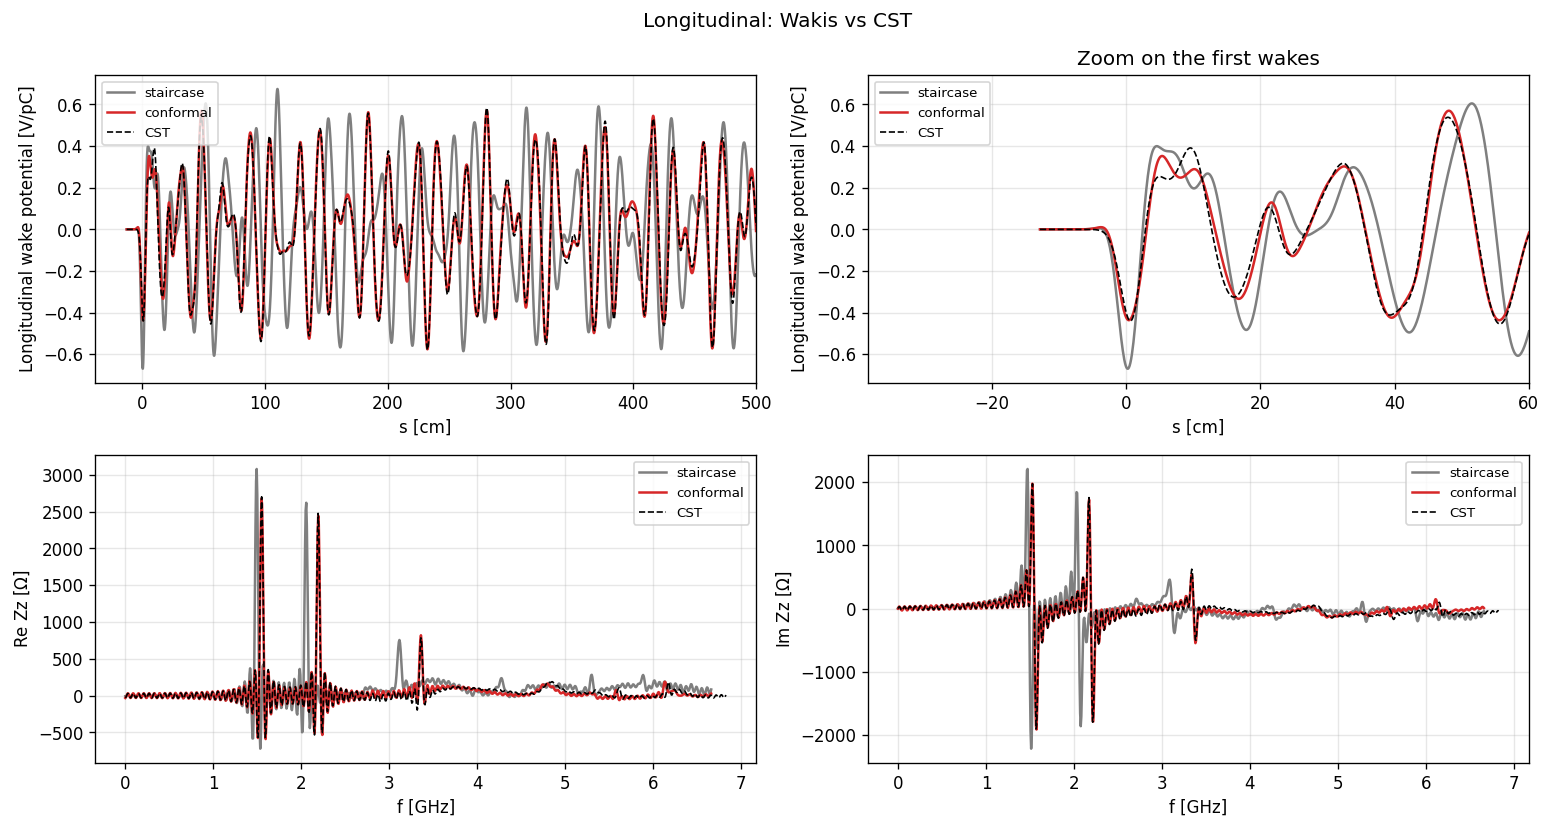

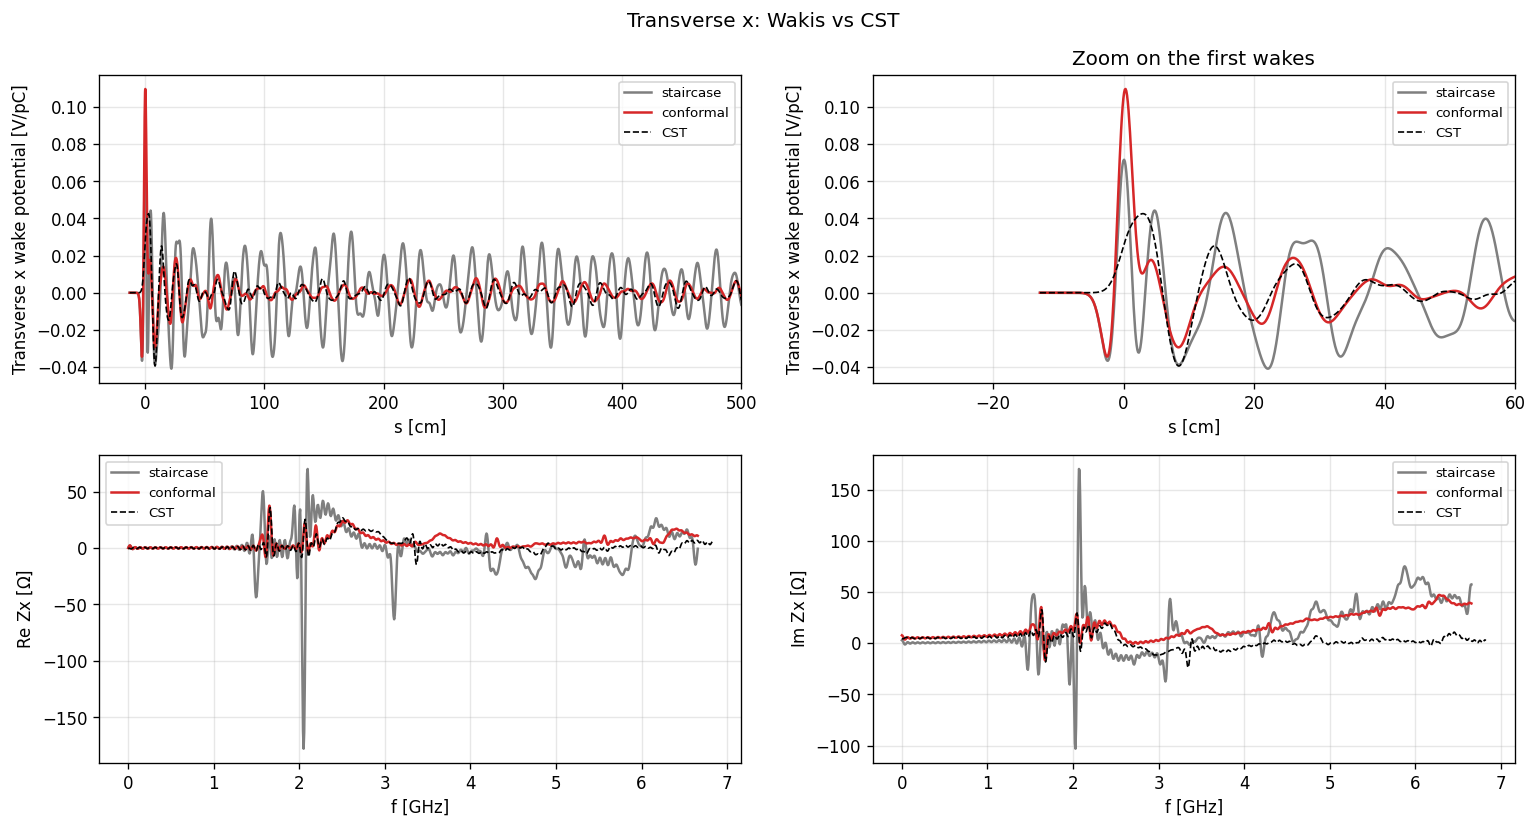

In [11]:
cst_style = dict(c="k", lw=1.0, ls="--", label="CST")
wakis_keys = {"z": ("WP", "f", "Z"), "x": ("WPx", "fx", "Zx")}


def compare_cst(plane, label, s_zoom=0.6):
    wp_key, f_key, z_key = wakis_keys[plane]
    fig, ax = plt.subplots(2, 2, figsize=[13, 7], dpi=120)
    for name, wake in wakes.items():
        ax[0, 0].plot(wake.s * 1e2, getattr(wake, wp_key), label=name, **styles[name])
        ax[0, 1].plot(wake.s * 1e2, getattr(wake, wp_key), label=name, **styles[name])
        ax[1, 0].plot(
            getattr(wake, f_key) * 1e-9,
            np.real(getattr(wake, z_key)),
            label=name,
            **styles[name],
        )
        ax[1, 1].plot(
            getattr(wake, f_key) * 1e-9,
            np.imag(getattr(wake, z_key)),
            label=name,
            **styles[name],
        )
    for a in ax[0]:
        a.plot(cst_s[plane] * 1e2, cst[f"W_{plane}"][:, 1], **cst_style)
    ax[1, 0].plot(cst_f[plane] * 1e-9, cst_Z[plane].real, **cst_style)
    ax[1, 1].plot(cst_f[plane] * 1e-9, cst_Z[plane].imag, **cst_style)

    ax[0, 0].set(
        xlabel="s [cm]",
        ylabel=f"{label} wake potential [V/pC]",
        xlim=(None, wakelength * 1e2),
    )
    ax[0, 1].set(
        xlabel="s [cm]",
        ylabel=f"{label} wake potential [V/pC]",
        xlim=(None, s_zoom * 1e2),
        title="Zoom on the first wakes",
    )
    ax[1, 0].set(xlabel="f [GHz]", ylabel=f"Re Z{plane} [$\\Omega$]")
    ax[1, 1].set(xlabel="f [GHz]", ylabel=f"Im Z{plane} [$\\Omega$]")
    for a in ax.flat:
        a.grid(alpha=0.3)
        a.legend(fontsize=8)
    fig.suptitle(f"{label}: Wakis vs CST")
    fig.tight_layout()
    fig.savefig(results_folder / f"cst_comparison_{plane}.png")
    plt.show()


compare_cst("z", "Longitudinal")
compare_cst("x", "Transverse x")

### Quantitative comparison

* Wake error: RMS of the difference to CST (Wakis interpolated onto the CST `s` samples), relative to the
  RMS of the CST wake, separately for the bunch passage (s < 10 cm) and the long-range wake (s > 10 cm).
* Resonances: the four strongest resonances (most prominent local maxima of |Z|) of each run, sorted
  by frequency.

In [12]:
from scipy.signal import find_peaks

for plane, label in (("z", "Longitudinal"), ("x", "Transverse x")):
    wp_key, f_key, z_key = wakis_keys[plane]
    s_ref, w_ref = cst_s[plane], cst[f"W_{plane}"][:, 1]
    print(f"\n{label}: relative RMS wake error vs CST (s < 10 cm, s > 10 cm)")
    for name, wake in wakes.items():
        w = np.interp(s_ref, wake.s, getattr(wake, wp_key))
        errors = [
            np.sqrt(np.mean((w[m] - w_ref[m]) ** 2) / np.mean(w_ref[m] ** 2))
            for m in (s_ref < 0.1, s_ref >= 0.1)
        ]
        print(f"  {name:10s}: {errors[0]:.3f}, {errors[1]:.3f}")

    spectra = {"CST": (cst_f[plane], cst_Z[plane])}
    spectra.update(
        {name: (getattr(w, f_key), getattr(w, z_key)) for name, w in wakes.items()}
    )
    print(f"{label}: strongest resonances, frequency [GHz] / |Z| [Ohm]")
    print("".join(f"{name:>20s}" for name in spectra))
    rows = []
    for f, Z in spectra.values():
        peaks, props = find_peaks(np.abs(Z), prominence=0)
        strongest = np.sort(peaks[np.argsort(props["prominences"])[-4:]])
        rows.append([f"{f[k] * 1e-9:7.3f} / {np.abs(Z[k]):6.1f}" for k in strongest])
    for row in zip(*rows):
        print("".join(f"{entry:>20s}" for entry in row))


Longitudinal: relative RMS wake error vs CST (s < 10 cm, s > 10 cm)
  staircase : 0.527, 1.527
  conformal : 0.214, 0.077
Longitudinal: strongest resonances, frequency [GHz] / |Z| [Ohm]
                 CST           staircase           conformal
      1.461 /  611.1      1.405 /  686.9      1.547 / 2696.3
      1.550 / 2701.2      1.493 / 3083.6      2.192 / 2447.7
      2.191 / 2477.3      2.056 / 2630.6      2.280 /  558.3
      3.358 /  798.5      3.115 /  756.0      3.359 /  820.2

Transverse x: relative RMS wake error vs CST (s < 10 cm, s > 10 cm)
  staircase : 1.095, 3.713
  conformal : 1.103, 0.560
Transverse x: strongest resonances, frequency [GHz] / |Z| [Ohm]
                 CST           staircase           conformal
      1.645 /   38.3      1.561 /   52.6      1.642 /   40.8
      2.055 /   31.5      2.063 /  188.8      2.050 /   30.6
      2.498 /   28.0      3.108 /   63.2      2.179 /   28.2
      3.345 /   23.8      5.877 /   75.3      2.498 /   28.1


## Export plot data

All curves of the comparison as CSV files in `<results_folder>/plotdata/`, one file per quantity and
source: `WP`, `WPx`, `WPy` (s [m], wake potential [V/pC]) and `Z`, `Zx`, `Zy` (f [Hz], Re and Im of the
impedance [Ohm]). Sources: `staircase`, `conformal` and `CST`. CST provides no vertical plane, and its
transverse impedance is stored in the Wakis sign convention (see above).

In [13]:
plotdata = results_folder / "plotdata"
plotdata.mkdir(exist_ok=True)


def export(name, source, x, y, x_label):
    """Write one curve: real data as one column, complex data as Re and Im columns."""
    columns = [x, y] if np.isrealobj(y) else [x, y.real, y.imag]
    header = (
        f"{x_label},{name} [V/pC]"
        if np.isrealobj(y)
        else f"{x_label},Re {name} [Ohm],Im {name} [Ohm]"
    )
    np.savetxt(
        plotdata / f"{name}_{source}.csv",
        np.column_stack(columns),
        delimiter=",",
        header=header,
    )


for source, wake in wakes.items():
    for name in ("WP", "WPx", "WPy"):
        export(name, source, wake.s, getattr(wake, name), "s [m]")
    for name, f_key in (("Z", "f"), ("Zx", "fx"), ("Zy", "fy")):
        export(name, source, getattr(wake, f_key), getattr(wake, name), "f [Hz]")

for plane, suffix in (("z", ""), ("x", "x")):
    export(f"WP{suffix}", "CST", cst_s[plane], cst[f"W_{plane}"][:, 1], "s [m]")
    export(f"Z{suffix}", "CST", cst_f[plane], cst_Z[plane], "f [Hz]")

print(sorted(path.name for path in plotdata.iterdir()))

['WP_CST.csv', 'WP_conformal.csv', 'WP_staircase.csv', 'WPx_CST.csv', 'WPx_conformal.csv', 'WPx_staircase.csv', 'WPy_conformal.csv', 'WPy_staircase.csv', 'Z_CST.csv', 'Z_conformal.csv', 'Z_staircase.csv', 'Zx_CST.csv', 'Zx_conformal.csv', 'Zx_staircase.csv', 'Zy_conformal.csv', 'Zy_staircase.csv']


### Observations

* **Longitudinal.** The conformal run reproduces the CST wake over the full 5 m (relative RMS error ~8 %
  after the bunch passage) and the CST resonances at 1.46, 1.55, 2.19 and 3.36 GHz within ~5 MHz and a
  few percent in amplitude, already on this coarse grid. The staircase resonances are shifted by
  50-240 MHz, so its long-range wake runs out of phase with CST.
* **Transverse x, long-range.** The conformal run reproduces the CST dipole resonances (1.64, 2.05,
  2.50 GHz) in frequency and amplitude; the staircase run adds the spurious peak at 2.06 GHz
  (monopole coupling, see the symmetry check above).
* **Transverse x, bunch passage.** Both Wakis runs show a narrow positive spike at s ≈ 0 (conformal
  0.11 V/pC) that CST does not have; in the spectrum it appears as a broadband Im Zx that rises with
  frequency. `WPx` at the test position x = 0 is a 3-point derivative over the lines x = -dx, 0, +dx,
  and here +dx = 4.875 mm is the source line itself, so the beam's own field on that line likely enters
  the derivative. To check: a transverse cell size below the 5 mm offset (e.g. `Nx = Ny = 65`, dx =
  2.44 mm), so that the source line is outside the derivative stencil.